# Ablation Study Analysis

This notebook analyzes the performance of Pretrained vs Finetuned LLaVA models when layers are ablated.
It loads evaluation results, normalizes them, and visualizes the degradation in performance.

In [1]:
import json
import os
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# Set plot style for publication quality
plt.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 14,
    'axes.labelsize': 13,
    'xtick.labelsize': 11,
    'ytick.labelsize': 11,
    'legend.fontsize': 11,
    'figure.titlesize': 16,
    'lines.linewidth': 2,
    'lines.markersize': 6,
    'axes.grid': True,
    'grid.alpha': 0.3
})

# ==========================================
# CONFIGURATION
# ==========================================

PROJECT_ROOT = Path.home() / "multimodal_finetuned_representations"
RESULTS_DIR = PROJECT_ROOT / "results/ablations"
PLOTS_DIR = PROJECT_ROOT / "plots/ablations"

# Ensure output directory exists
PLOTS_DIR.mkdir(parents=True, exist_ok=True)

MODELS = {
    "Pretrained": "l11p_llava-v1.5-7b-pretrained-lbasile",
    "Finetuned": "lbasile_llava_7b"
}

# Expected layers to be ablated (even numbers from 0 to 32)
EXPECTED_LAYERS = list(range(0, 34, 2))

# Task Configurations
TASKS = {
    "gqa": {
        "file_name": "gqa.jsonl",
        "score_key": "exact_match,none",
        "max_val": 1.0,
        "label": "GQA"
    },
    "mmbench_en_dev": {
        "file_name": "mmbench_en_dev.jsonl",
        "score_key": "gpt_eval_score,none",
        "max_val": 100.0,
        "label": "MMBench"
    },
    "mme": {
        "file_name": "mme.jsonl",
        "score_key": ["mme_perception_score,none", "mme_cognition_score,none"] ,
        "max_val": 2000.0,
        "label": "MME"
    },
    "scienceqa_img": {
        "file_name": "scienceqa_img.jsonl",
        "score_key": "exact_match,none",
        "max_val": 1.0,
        "label": "ScienceQA"
    },
    "vqav2_val": {
        "file_name": "vqav2_val.jsonl",
        "score_key": "exact_match,none",
        "max_val": 1.0,
        "label": "VQAv2"
    }
}


In [2]:
# ==========================================
# DATA LOADING FUNCTIONS
# ==========================================

def load_task_data(model_dir_name, task_name, task_config):
    filepath = RESULTS_DIR / model_dir_name / task_name / task_config["file_name"]
    if not filepath.exists():
        print(f"[WARNING] File not found: {filepath}")
        return {}
    
    data = {}
    with open(filepath, 'r') as f:
        for line in f:
            try:
                entry = json.loads(line)
                layer = entry.get("layers_ablated")
                
                if layer is None:
                    continue
                    
                # Handle MME sum
                if isinstance(task_config["score_key"], list):
                    score = 0
                    for key in task_config["score_key"]:
                        score += entry.get(key, 0)
                else:
                    score = entry.get(task_config["score_key"], 0)
                
                data[layer] = score
            except json.JSONDecodeError:
                print(f"[ERROR] Failed to decode JSON line in {filepath}")
            except Exception as e:
                print(f"[ERROR] Processing {filepath}: {e}")
                
    return data

def process_and_normalize(raw_data, task_config, expected_layers):
    """
    Returns an array of shape (len(expected_layers), 2)
    Column 0: Layer Index
    Column 1: Normalized Score (or NaN if missing)
    """
    result = []
    max_val = task_config["max_val"]
    
    missing_layers = []
    
    for layer in expected_layers:
        if layer in raw_data:
            val = raw_data[layer]
            norm_val = val / max_val
            result.append([layer, norm_val])
        else:
            result.append([layer, np.nan])
            missing_layers.append(layer)
            
    return np.array(result), missing_layers

In [3]:
# ==========================================
# EXECUTION & REPORTING
# ==========================================

model_results = {}

print("--- Data Loading Report ---")

for model_label, model_dir in MODELS.items():
    print(f"Model: {model_label} ({model_dir})")
    model_results[model_label] = {}
    
    for task_key, task_conf in TASKS.items():
        # 1. Load Data
        raw_data = load_task_data(model_dir, task_key, task_conf)
        
        # 2. Process and Normalize
        processed_data, missing = process_and_normalize(raw_data, task_conf, EXPECTED_LAYERS)
        
        # 3. Store Results
        model_results[model_label][task_key] = processed_data
        
        # 4. Report
        found_count = len(raw_data)
        print(f"  Task: {task_conf['label']:<10} | Entries: {found_count:<3} | ", end="")
        
        if missing:
            print(f"[WARNING] Missing layers: {missing}")
        else:
            print("All layers present.")

--- Data Loading Report ---
Model: Pretrained (l11p_llava-v1.5-7b-pretrained-lbasile)
  Task: GQA        | Entries: 17  | All layers present.
  Task: MMBench    | Entries: 16  | [WARNING] Missing layers: [2]
  Task: MME        | Entries: 17  | All layers present.
  Task: ScienceQA  | Entries: 17  | All layers present.
  Task: VQAv2      | Entries: 17  | All layers present.
Model: Finetuned (lbasile_llava_7b)
  Task: GQA        | Entries: 17  | All layers present.
  Task: MMBench    | Entries: 17  | All layers present.
  Task: MME        | Entries: 17  | All layers present.
  Task: ScienceQA  | Entries: 17  | All layers present.
  Task: VQAv2      | Entries: 17  | All layers present.


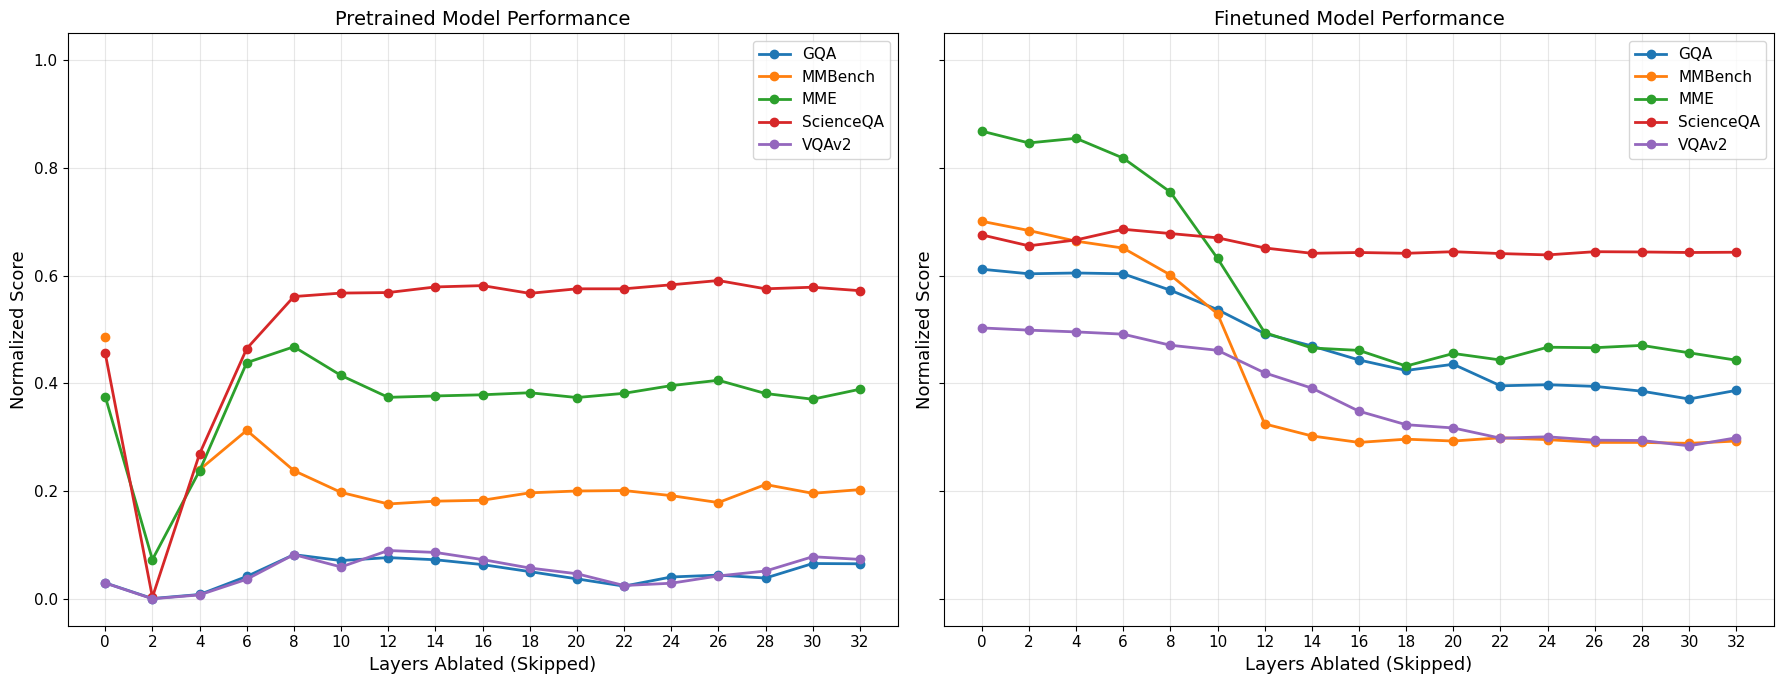

Figure 1 saved to: /u/dssc/lpalaciosflores/multimodal_finetuned_representations/plots/ablations/ablation_by_model.png


In [4]:
# ==========================================
# FIGURE 1: Detailed Performance per Model
# ==========================================

fig1, axes = plt.subplots(1, 2, figsize=(18, 7), sharey=True)

# Helper to plot one model's data on an axis
def plot_model_details(ax, model_label):
    data_dict = model_results[model_label]
    
    for task_key, task_conf in TASKS.items():
        data = data_dict[task_key]
        layers = data[:, 0]
        scores = data[:, 1]
        
        # Mask NaNs for plotting lines properly (though matplotlib usually handles them by breaking the line)
        # We plot directly; gaps will appear where data is missing.
        ax.plot(layers, scores, marker='o', label=task_conf['label'])

    ax.set_title(f"{model_label} Model Performance")
    ax.set_xlabel("Layers Ablated (Skipped)")
    ax.set_ylabel("Normalized Score")
    ax.set_ylim(-0.05, 1.05)
    ax.set_xticks(EXPECTED_LAYERS)
    ax.legend()

# Plot Pretrained (0,0)
plot_model_details(axes[0], "Pretrained")

# Plot Finetuned (0,1)
plot_model_details(axes[1], "Finetuned")

plt.tight_layout()
save_path1 = PLOTS_DIR / "ablation_by_model.png"
plt.savefig(save_path1, dpi=300)
plt.show()
print(f"Figure 1 saved to: {save_path1}")

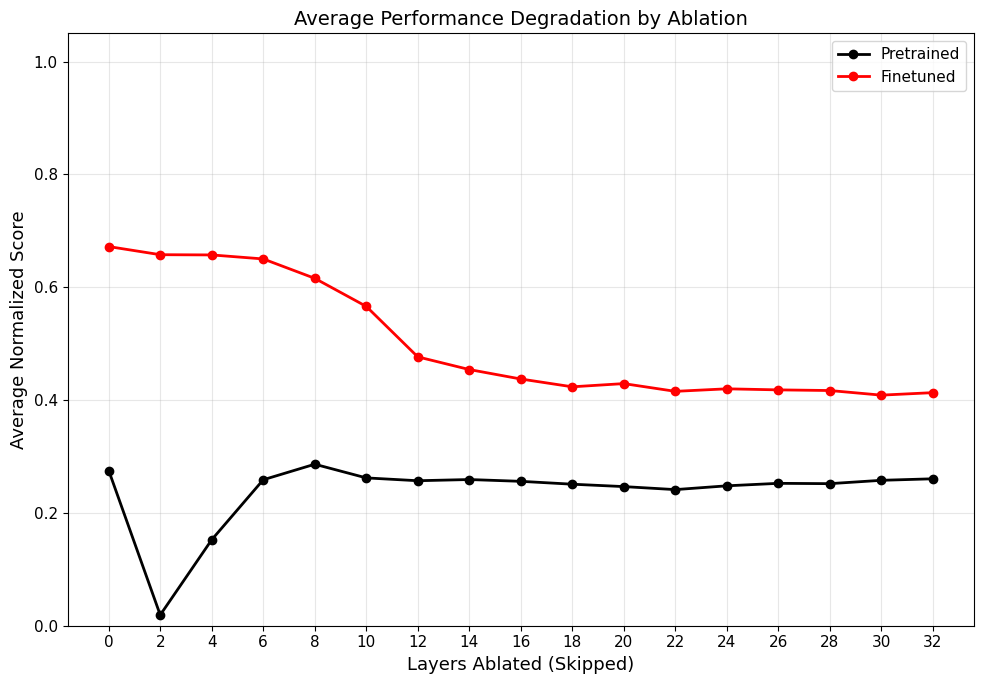

Figure 2 saved to: /u/dssc/lpalaciosflores/multimodal_finetuned_representations/plots/ablations/ablation_averaged.png


In [5]:
# ==========================================
# FIGURE 2: Averaged Performance
# ==========================================

fig2, ax = plt.subplots(figsize=(10, 7))

colors = {"Pretrained": "black", "Finetuned": "red"}

for model_label in MODELS.keys():
    task_data_list = []
    
    # Collect all task arrays
    for task_key in TASKS.keys():
        data = model_results[model_label][task_key]
        # Extract just the scores (column 1)
        task_data_list.append(data[:, 1])
        
    # Stack and compute mean, ignoring NaNs
    # Shape: (num_tasks, num_layers)
    stacked_data = np.vstack(task_data_list)
    
    # Compute mean across tasks (axis 0)
    mean_scores = np.nanmean(stacked_data, axis=0)
    
    # Plot
    ax.plot(EXPECTED_LAYERS, mean_scores, 
            marker='o', 
            label=model_label, 
            color=colors.get(model_label, 'blue'))

ax.set_title("Average Performance Degradation by Ablation")
ax.set_xlabel("Layers Ablated (Skipped)")
ax.set_ylabel("Average Normalized Score")
ax.set_ylim(0, 1.05)
ax.set_xticks(EXPECTED_LAYERS)
ax.legend()

plt.tight_layout()
save_path2 = PLOTS_DIR / "ablation_averaged.png"
plt.savefig(save_path2, dpi=300)
plt.show()
print(f"Figure 2 saved to: {save_path2}")